# Attenuation correction on S, C and X band

**radar-wow stage 4.** Heavy rain absorbs part of the beam, so everything behind a storm looks
weaker (Z) and rounder (ZDR) than it is. PHIDP tells us how much rain the beam crossed, so it
tells us how much to add back.

| algorithm | paper | idea |
|---|---|---|
| `LinearPhiAttenuation` | Bringi et al. 2001 (baseline used there) | PIA = alpha x PHIDP |
| `Testud2000ZPHI` | Testud et al. 2000, JTECH, doi:10.1175/1520-0426(2000)017<0332:TRPAAT>2.0.CO;2 | spread the PHIDP-given total along the ray following the Z profile |
| `Bringi2001SelfConsistent` | Bringi, Keenan & Chandrasekar 2001, IEEE TGRS, doi:10.1109/36.951081 | ZPHI with the alpha per ray that best reproduces the measured PHIDP |

PIA = two-way path-integrated attenuation (dB). Corrected Z = Z + PIA; corrected ZDR = ZDR + (beta/alpha) PIA,
applied only to gates with real signal (adding PIA to noise would create fake echo behind storms).

In [1]:
# Colab: uncomment to install
!pip install -q "git+https://github.com/radar-wow/radarwow-core" "git+https://github.com/radar-wow/radarwow-kdp" "git+https://github.com/radar-wow/radarwow-attenuation"

zsh:1: command not found: pip


In [2]:
import time
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from radarwow.attenuation import Bringi2001SelfConsistent, LinearPhiAttenuation, Testud2000ZPHI, synthetic_attenuated_sweep
from radarwow.core import load_band, load_sample
from radarwow.core.noise import signal_mask
from radarwow.core.plotting import ppi
from radarwow.kdp import Vulpiani2012KDP

FIG = "../docs/figures"
METHODS = {"Linear PHIDP": LinearPhiAttenuation, "ZPHI (Testud 2000)": Testud2000ZPHI, "Self-consistent (Bringi 2001)": Bringi2001SelfConsistent}

## 1. Synthetic truth
Rays with two rain cells where A = a Z^b and KDP = A / alpha_true exactly. We test each band with
the band's default alpha (alpha matches) and C band with alpha_true = 0.11 while the default is 0.08
(alpha wrong): real rain does not follow one fixed alpha.

| band | true alpha | true PIA at last signal gates (dB) | rain lost to extinction (km) | method | Z error (dB) | ZDR error (dB) | alpha used |
|---|---|---|---|---|---|---|---|
| S | 0.015 | 1.6 | 0 | Linear PHIDP | 0.02 | 0.00 | 0.015 |
| S | 0.015 | 1.6 | 0 | ZPHI (Testud 2000) | 0.02 | 0.00 | 0.015 |
| S | 0.015 | 1.6 | 0 | Self-consistent (Bringi 2001) | 0.02 | 0.00 | 0.015 |
| C | 0.08 | 9.3 | 0 | Linear PHIDP | 0.09 | 0.02 | 0.080 |
| C | 0.08 | 9.3 | 0 | ZPHI (Testud 2000) | 0.09 | 0.02 | 0.080 |
| C | 0.08 | 9.3 | 0 | Self-consistent (Bringi 2001) | 0.11 | 0.02 | 0.080 |
| C | 0.11 | 9.3 | 0 | Linear PHIDP | 2.56 | 0.64 | 0.080 |
| C | 0.11 | 9.3 | 0 | ZPHI (Testud 2000) | 2.53 | 0.63 | 0.080 |
| C | 0.11 | 9.3 | 0 | Self-consistent (Bringi 2001) | 0.48 | 0.63 | 0.107 |
| X | 0.28 | 25.9 | 7 | Linear PHIDP | 0.24 | 0.04 | 0.280 |
| X | 0.28 | 25.9 | 7 | ZPHI (Testud 2000) | 0.31 | 0.06 | 0.280 |
| X | 0.28 | 25.9 | 7 | Self-consistent (Bringi 2001) | 0.35 | 0.06 | 0.280 |

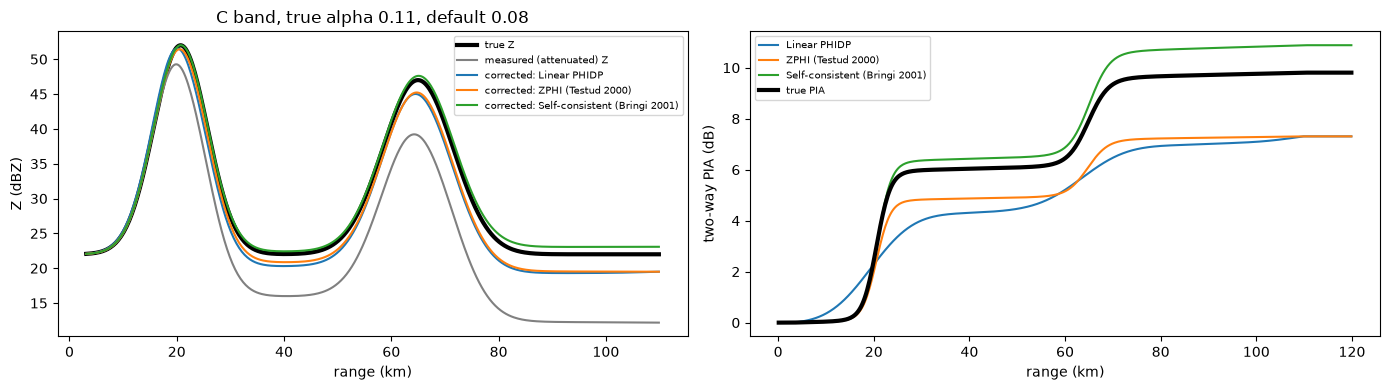

In [3]:
cases = [("S", 0.015, 0.004, 0.06), ("C", 0.08, 0.02, 0.35), ("C", 0.11, 0.0275, 0.35), ("X", 0.28, 0.05, 1.0)]


def far_end(ds, n=40):
    """Mask of the last n gates per ray that still have signal (SNR > 3 dB)."""
    sig = ds["SNRH"].values > 3
    keep = np.zeros_like(sig)
    for i in range(sig.shape[0]):
        idx = np.flatnonzero(sig[i])
        keep[i, idx[-n:]] = True
    return keep


rows = ["| band | true alpha | true PIA at last signal gates (dB) | rain lost to extinction (km) | method | Z error (dB) | ZDR error (dB) | alpha used |",
        "|---|---|---|---|---|---|---|---|"]
for band, a_true, beta, a50 in cases:
    ds = synthetic_attenuated_sweep(alpha_true=a_true, beta=beta, a_at_50dbz=a50)
    far = far_end(ds)
    rain = np.isfinite(ds["Z_TRUE"].values)
    lost_km = float(np.median((rain & ~(ds["SNRH"].values > 3)).sum(axis=1))) * 0.25
    pia_end = float(np.nanmedian(ds["PIA_TRUE"].values[far]))
    for label, cls in METHODS.items():
        out = cls()(ds, band=band)
        ez = float(np.nanmedian(np.abs(out["DBZH"].values - ds["Z_TRUE"].values)[far]))
        ed = float(np.nanmedian(np.abs(out["ZDR"].values - ds["ZDR_TRUE"].values)[far]))
        al = float(np.median(out["ALPHA"].values)) if "ALPHA" in out else load_band(band)["zphi_alpha"]
        rows.append(f"| {band} | {a_true} | {pia_end:.1f} | {lost_km:.0f} | {label} | {ez:.2f} | {ed:.2f} | {al:.3f} |")
display(Markdown("\n".join(rows)))

ds = synthetic_attenuated_sweep(alpha_true=0.11, beta=0.0275)
r = ds["range"].values / 1e3
i = 5
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(r, ds["Z_TRUE"].values[i], "k", lw=3, label="true Z")
ax[0].plot(r, ds["DBZH"].values[i], color="grey", label="measured (attenuated) Z")
for label, cls in METHODS.items():
    out = cls()(ds, band="C")
    ax[0].plot(r, out["DBZH"].values[i], label=f"corrected: {label}")
    ax[1].plot(r, out["PIA"].values[i], label=label)
ax[1].plot(r, ds["PIA_TRUE"].values[i], "k", lw=3, label="true PIA")
ax[0].set(xlabel="range (km)", ylabel="Z (dBZ)", title="C band, true alpha 0.11, default 0.08")
ax[1].set(xlabel="range (km)", ylabel="two-way PIA (dB)")
for a in ax:
    a.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{FIG}/01_synthetic.png", dpi=110)
plt.show()

With the right alpha all three methods recover Z to well under 1 dB wherever signal survives, even
behind 20+ dB of loss at X band. With the wrong alpha the fixed-alpha methods miss by ~2.5 dB at the far
end; the self-consistent method finds alpha from the data and stays near 0.5 dB (its ZDR error stays,
because beta/alpha is fixed from the band config: the paper's ZDR constraint is not implemented yet).

**Signal extinction (X band).** Behind the strongest cells the rain at the far end drops below the
receiver noise and is simply gone: no correction can bring it back. Those gates are left uncorrected
(they have no signal) and must be flagged for later stages; this is the main reason X band radars are
used at short range or in networks.

**When can alpha be fitted?** Only when the path attenuates noticeably. With little attenuation the
ZPHI-implied PHIDP has the same shape for every alpha, and a free fit lands at an edge of the search
range by chance. So `Bringi2001SelfConsistent` fits alpha only on rays where default alpha x delta
PHIDP >= 3 dB, the best alpha is inside the range, and it improves the misfit by 10 %; other rays keep
the band default and are flagged in `ALPHA_FITTED`.

## 2. Real data
Pipeline per sweep: `open_volume` -> `Vulpiani2012KDP` (gives the cleaned PHIDP) -> attenuation.
Rain gates must form runs of at least 2 km: isolated noise gates far from the storm otherwise
pass the rhoHV test and create fake PHIDP rises.

In [4]:
samples = {"S": "nexrad_ktlx_s", "C": "arm_csapr2_c", "X": "arm_xsapr_x"}
data, results, timing = {}, {}, {}
for band, name in samples.items():
    ds = load_sample(name, sweeps=[0])["sweep_0"].to_dataset()
    data[band] = Vulpiani2012KDP()(ds, band=band)
    for label, cls in METHODS.items():
        t = time.time()
        results[(band, label)] = cls()(data[band], band=band)
        timing[(band, label)] = time.time() - t

rows = ["| band | method | PIA 99th pct (dB) | PIA max (dB) | rays with alpha fitted | fitted alpha median | runtime (s) |", "|---|---|---|---|---|---|---|"]
for (band, label), out in results.items():
    pia = out["PIA"].values
    nf = int(out["ALPHA_FITTED"].sum()) if "ALPHA_FITTED" in out else "-"
    am = f"{float(np.median(out['ALPHA'].values[out['ALPHA_FITTED'].values])):.3f}" if "ALPHA_FITTED" in out and out["ALPHA_FITTED"].any() else "-"
    rows.append(f"| {band} | {label} | {np.nanpercentile(pia, 99):.1f} | {np.nanmax(pia):.1f} | {nf} | {am} | {timing[(band, label)]:.2f} |")
display(Markdown("\n".join(rows)))

| band | method | PIA 99th pct (dB) | PIA max (dB) | rays with alpha fitted | fitted alpha median | runtime (s) |
|---|---|---|---|---|---|---|
| S | Linear PHIDP | 2.3 | 5.6 | - | - | 0.03 |
| S | ZPHI (Testud 2000) | 2.0 | 5.6 | - | - | 0.06 |
| S | Self-consistent (Bringi 2001) | 2.0 | 5.6 | 0 | - | 1.02 |
| C | Linear PHIDP | 15.9 | 20.8 | - | - | 0.03 |
| C | ZPHI (Testud 2000) | 15.9 | 20.7 | - | - | 0.02 |
| C | Self-consistent (Bringi 2001) | 19.7 | 25.8 | 25 | 0.091 | 0.27 |
| X | Linear PHIDP | 9.1 | 37.3 | - | - | 0.02 |
| X | ZPHI (Testud 2000) | 9.1 | 36.0 | - | - | 0.02 |
| X | Self-consistent (Bringi 2001) | 9.1 | 36.0 | 3 | 0.172 | 0.18 |

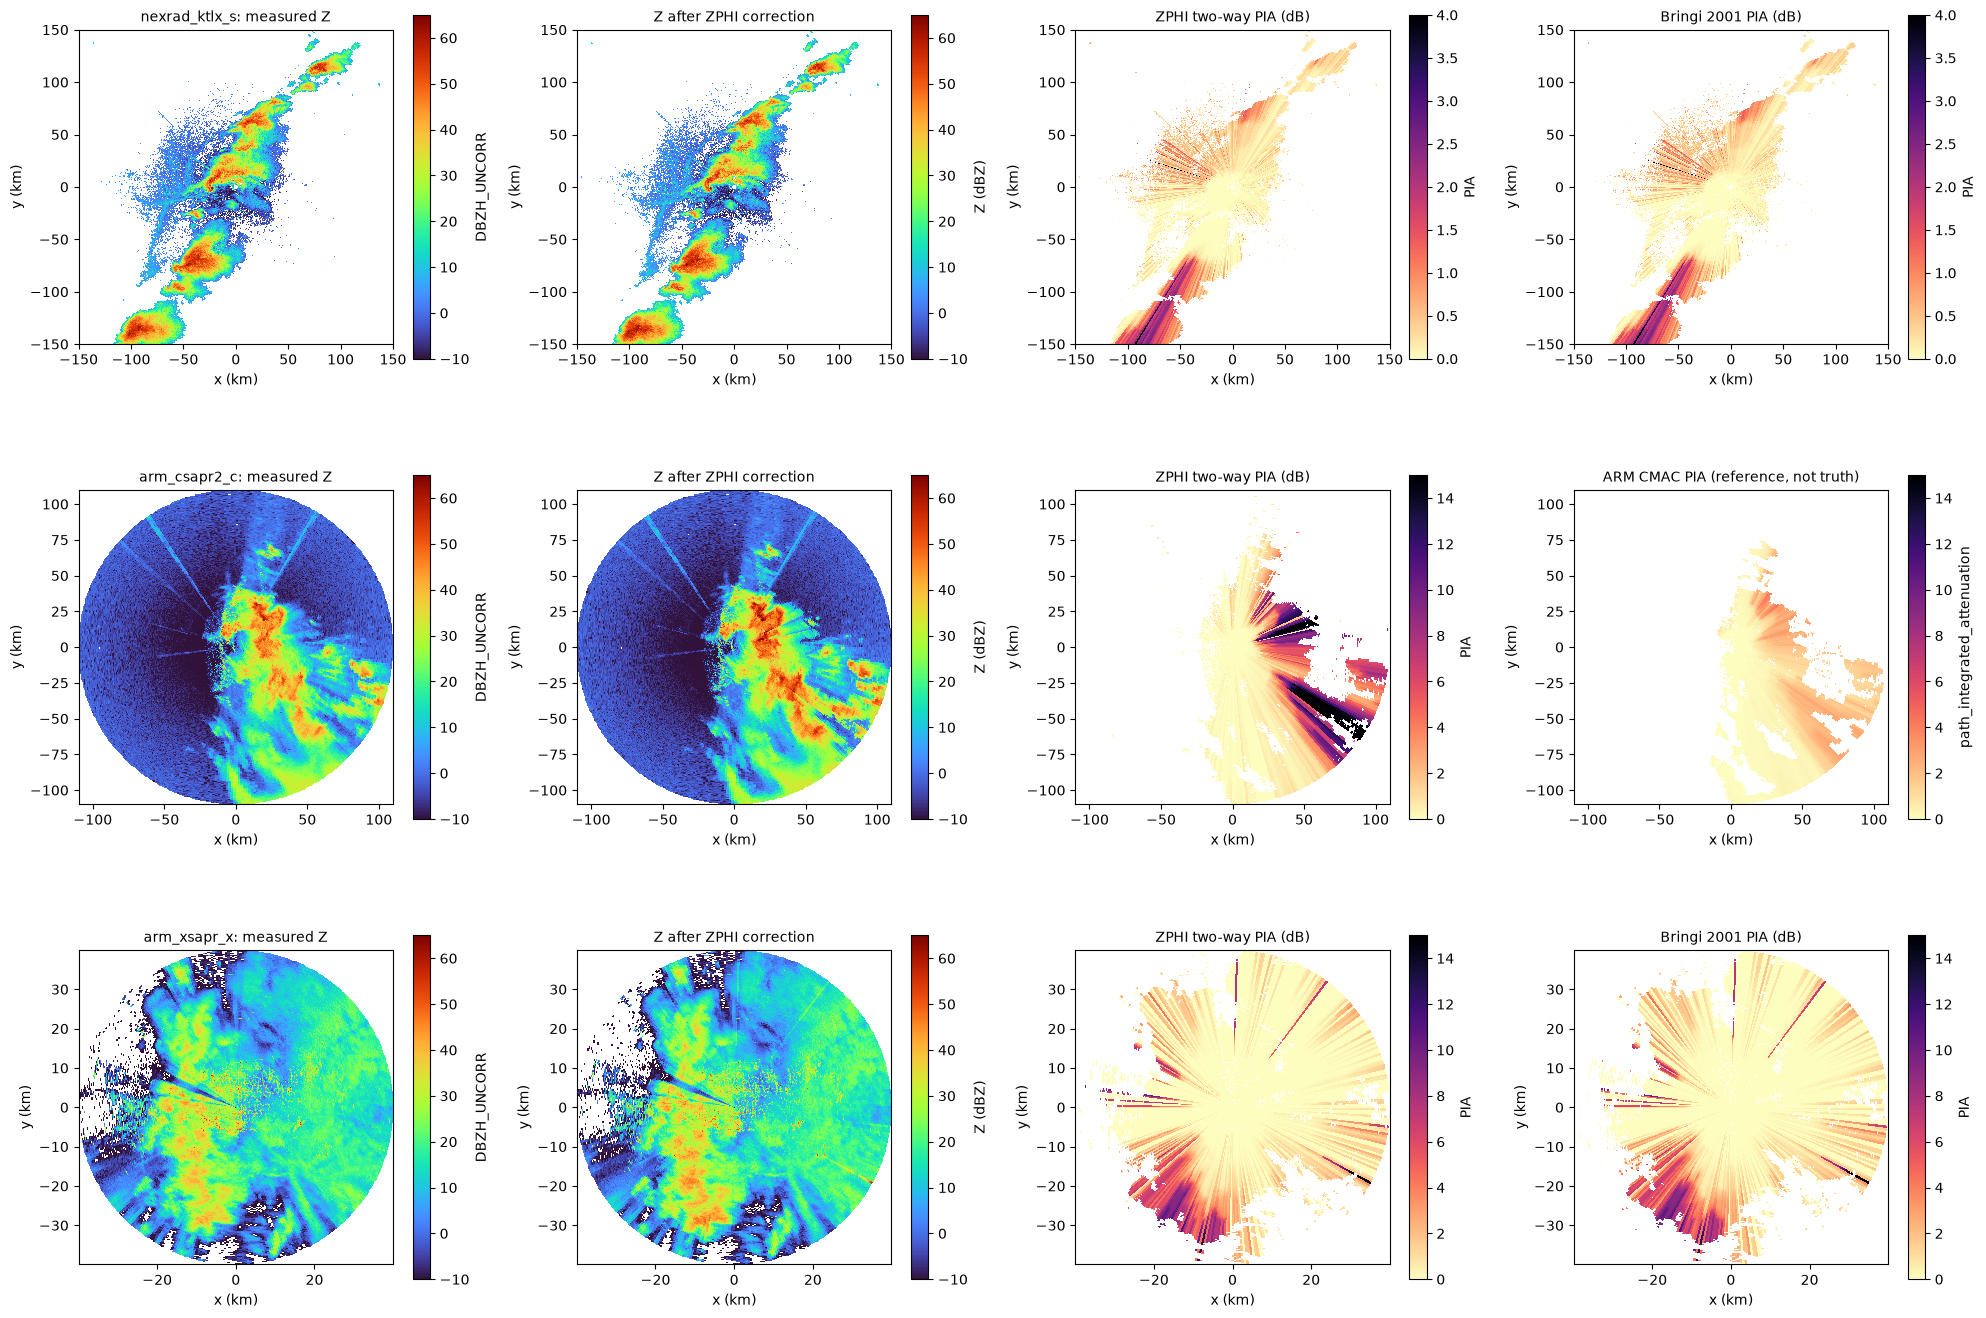

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for row, (band, name) in enumerate(samples.items()):
    out = results[(band, "ZPHI (Testud 2000)")]
    km = min(150.0, float(out["range"].values[-1]) / 1e3)
    ppi(out, "DBZH_UNCORR", ax=axes[row, 0], max_km=km, title=f"{name}: measured Z", cmap="turbo", vmin=-10, vmax=65)
    ppi(out, "DBZH", ax=axes[row, 1], max_km=km, title="Z after ZPHI correction")
    out = out.assign(PIA=out["PIA"].where(signal_mask(out)))
    ppi(out, "PIA", ax=axes[row, 2], max_km=km, title="ZPHI two-way PIA (dB)", cmap="magma_r", vmin=0, vmax={"S": 4, "C": 15, "X": 15}[band])
    if "path_integrated_attenuation" in data[band]:
        ppi(data[band], "path_integrated_attenuation", ax=axes[row, 3], max_km=km, title="ARM CMAC PIA (reference, not truth)", cmap="magma_r", vmin=0, vmax=15)
    else:
        b = results[(band, "Self-consistent (Bringi 2001)")]
        ppi(b.assign(PIA=b["PIA"].where(signal_mask(b))), "PIA", ax=axes[row, 3], max_km=km, title="Bringi 2001 PIA (dB)", cmap="magma_r", vmin=0, vmax={"S": 4, "C": 15, "X": 15}[band])
fig.tight_layout()
fig.savefig(f"{FIG}/02_real_pia_ppi.png", dpi=95)
plt.show()

## 3. A physical check: ZDR in light rain behind the storm
Light rain (Z 20-30 dBZ after correction, rhoHV > 0.98) has small, nearly round drops, so its
ZDR should be about the same everywhere, whether or not a storm sits in front of it. Differential
attenuation makes light rain *behind* a storm look too low. If the correction works, the ZDR
behind the storm should move up to the ZDR of light rain with no storm in front.
(C band only: the X-SAPR ZDR is clipped at 0 and NEXRAD attenuation is small.)

In [6]:
rows = ["| method | light rain, PIA < 0.5 dB (reference) | light rain behind storm, PIA > 4 dB: before | after | gates behind |", "|---|---|---|---|---|"]
for label in METHODS:
    out = results[("C", label)]
    zc, rho, pia = out["DBZH"].values, out["RHOHV"].values, out["PIA"].values
    light = (zc > 20) & (zc < 30) & (rho > 0.98)
    if "height_over_iso0" in out:
        light &= out["height_over_iso0"].values < 0
    ref = np.nanmedian(out["ZDR"].values[light & (pia < 0.5)])
    behind = light & (pia > 4)
    rows.append(f"| {label} | {ref:+.2f} dB | {np.nanmedian(out['ZDR_UNCORR'].values[behind]):+.2f} dB | "
                f"{np.nanmedian(out['ZDR'].values[behind]):+.2f} dB | {int(behind.sum())} |")
display(Markdown("\n".join(rows)))

| method | light rain, PIA < 0.5 dB (reference) | light rain behind storm, PIA > 4 dB: before | after | gates behind |
|---|---|---|---|---|
| Linear PHIDP | +0.17 dB | -1.52 dB | -0.18 dB | 1130 |
| ZPHI (Testud 2000) | +0.15 dB | -1.47 dB | -0.12 dB | 1176 |
| Self-consistent (Bringi 2001) | +0.15 dB | -1.45 dB | -0.08 dB | 1117 |

## 4. Comparison with ARM's own correction (C band)
ARM's CMAC chain also corrects attenuation; it is a reference from another processing chain, not
truth. Its PHIDP rises less than ours across the storm (see the KDP notebook, ray at 47.6 deg), so we
expect our PIA to be larger.

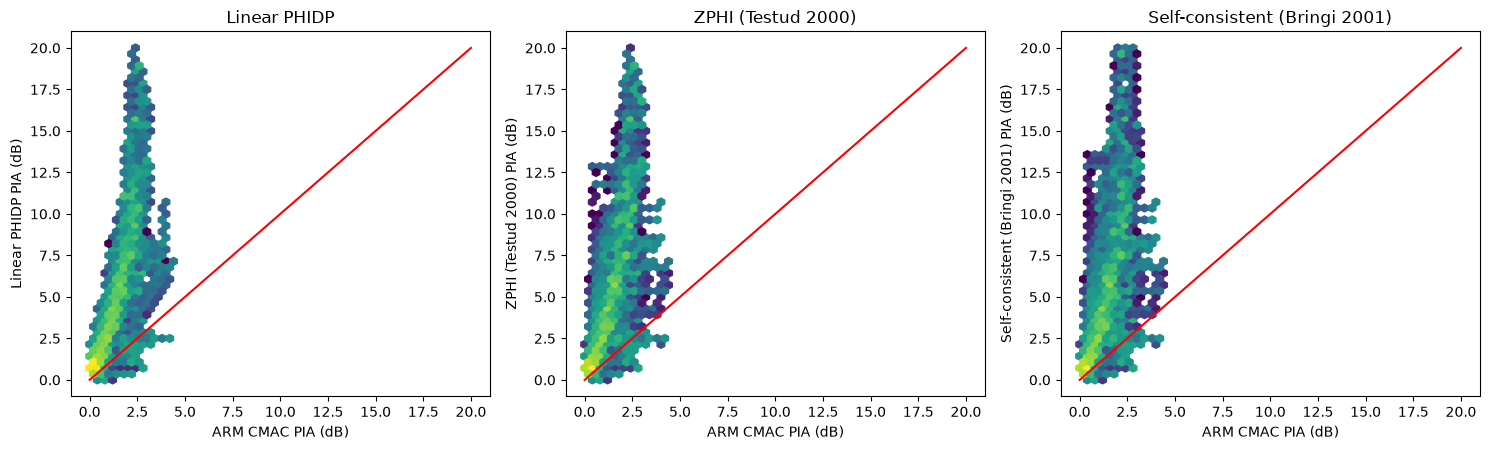

| method | r | median (ours - ARM) dB | n gates |
|---|---|---|---|
| Linear PHIDP | 0.76 | +1.95 | 67186 |
| ZPHI (Testud 2000) | 0.73 | +2.35 | 61020 |
| Self-consistent (Bringi 2001) | 0.68 | +2.24 | 60955 |

In [7]:
d = data["C"]
ref = d["path_integrated_attenuation"].values
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
rows = ["| method | r | median (ours - ARM) dB | n gates |", "|---|---|---|---|"]
for a, label in zip(ax, METHODS):
    pia = results[("C", label)]["PIA"].values
    m = np.isfinite(ref) & np.isfinite(pia) & ((ref > 0.5) | (pia > 0.5))
    a.hexbin(ref[m], pia[m], gridsize=50, bins="log", extent=(0, 20, 0, 20))
    a.plot([0, 20], [0, 20], "r")
    a.set(xlabel="ARM CMAC PIA (dB)", ylabel=f"{label} PIA (dB)", title=label)
    rows.append(f"| {label} | {np.corrcoef(ref[m], pia[m])[0, 1]:.2f} | {np.median(pia[m] - ref[m]):+.2f} | {m.sum()} |")
fig.tight_layout()
fig.savefig(f"{FIG}/03_vs_arm.png", dpi=110)
plt.show()
display(Markdown("\n".join(rows)))

## Takeaways
- With the right alpha all three methods recover synthetic Z to < 1 dB, at every band. Real rain varies
  alpha, and then only the self-consistent method keeps up, but alpha can only be fitted on rays that
  attenuate noticeably (none at S band here, a minority of C band rays).
- The result depends on the PHIDP we feed in. Requiring 2 km runs of rain gates removed fake PHIDP rises
  on two of three radars; the remaining difference to ARM's PIA follows from the different PHIDP rise.
- Open: the ZDR constraint for beta from Bringi 2001; hail and melting-layer attenuation (ZPHI assumes rain);
  wet-radome loss, which PHIDP cannot see.